# CASALS–3DEP vertical datum validation

This notebook audits the height-reference evidence and compares native Refh, H5 scalar hypotheses, a GEOID18-constrained 3D PROJ operation, and a separately calibrated empirical baseline for the 2024-11-12 and 2024-11-18 CASALS granules.

**Current status:** C7 is selected as `PROVISIONAL_NOT_DATUM_VERIFIED`. The 3DEP target and sampled Z passthrough are evidenced. The CASALS source realization, coordinate epoch, and height-processing conventions remain undocumented, so these results do not certify absolute elevation accuracy.

The computation writes experiment outputs only to `outputs/notebooks/10_3dep_elevation_validation/datum_comparison/`.

## 1. Data and Reference Frames

The first cell runs the comparison from the actual CASALS H5 files, current clipped 3DEP LAZ files, and small source EPT samples. It freezes the geometry-only selection split, audits H5 fields and product metadata, verifies sampled point identity/Z preservation, runs the XYZ transformation, compares candidates, freezes C7, and then evaluates the independent-test partition.

The CryoCloud L1B tutorial describes `refh` as WGS84 ellipsoidal height, but the H5 fields have no units, vertical CRS, realization, or coordinate epoch. That convention is therefore not sufficient to verify the source frame.

,granule,pulse count,H5 SHA-256
0,2024-11-12,3604480,637ba73ca9966b86d9243987916c0e60b8fec76c8690d4...
1,2024-11-18,3604480,dac3d5ed0116083f98944e8d6b0e86f6d812f0f5e4f196...


,granule,field,units,H5 attributes,median (m),max |free2mean − formula| (m)
0,2024-11-12,refh,None,{},-25.504444,NaN
1,2024-11-12,geoid,None,{},-36.832462,NaN
2,2024-11-12,geoid_free2mean,None,{},-0.019859,0.000001
3,2024-11-18,refh,None,{},-32.380623,NaN
4,2024-11-18,geoid,None,{},-37.431847,NaN
5,2024-11-18,geoid_free2mean,None,{},-0.005459,0.000006


,granule,work unit,project,target vertical CRS,geoid model,metadata conflict,identity matches,median ΔZ (m),max |ΔZ| (m),max ΔXY (m)
0,2024-11-12,MD_Southeast_1_2019,MD_Southeast_2019_D20,"NAVD88 height, EPSG:5703",GEOID18,True,11871,-0.005,0.005,0.007029
1,2024-11-18,NC_HurricaneFlorence_9_2020,NC_HurricaneFlorence_2020_D20,"NAVD88 height, EPSG:5703",GEOID18,False,11775,-0.005,0.005,0.006420


Sampled Z status: VERIFIED_SAMPLE_PASSTHROUGH — 0.01 m LAS quantization tolerance; sample only.


,granule,C7 rank,C7 accuracy (m),C7 grid,top alternative,alternative accuracy (m),available / unavailable
0,2024-11-12,3,2.015,us_noaa_g2018u0.tif,GEOID99 + NADCON5,1.14,14 / 0
1,2024-11-18,3,2.015,us_noaa_g2018u0.tif,GEOID99 + NADCON5,1.14,13 / 0


,granule,max inverse XY error (m),max inverse Z error (m),median vertical correction (m),max XY shift (m)
0,2024-11-12,2.000000e-09,0.0,35.894288,0.0
1,2024-11-18,2.000000e-09,0.0,36.368032,0.0


Frozen split SHA-256: cd714dd3057193bc9f510dfa34adfe19b2c28db628f2b93f41525a8a30f8b702


,granule,role,pulse count
0,2024-11-12,calibration_offset,8987
1,2024-11-12,candidate_selection,8987
2,2024-11-12,independent_test,17171
3,2024-11-18,calibration_offset,3570
4,2024-11-18,candidate_selection,3570
5,2024-11-18,independent_test,8924


Output directory: C:\Users\zhong267\OneDrive - purdue.edu\CASALS\outputs\notebooks\10_3dep_elevation_validation\datum_comparison
Artifact files including manifest: 35


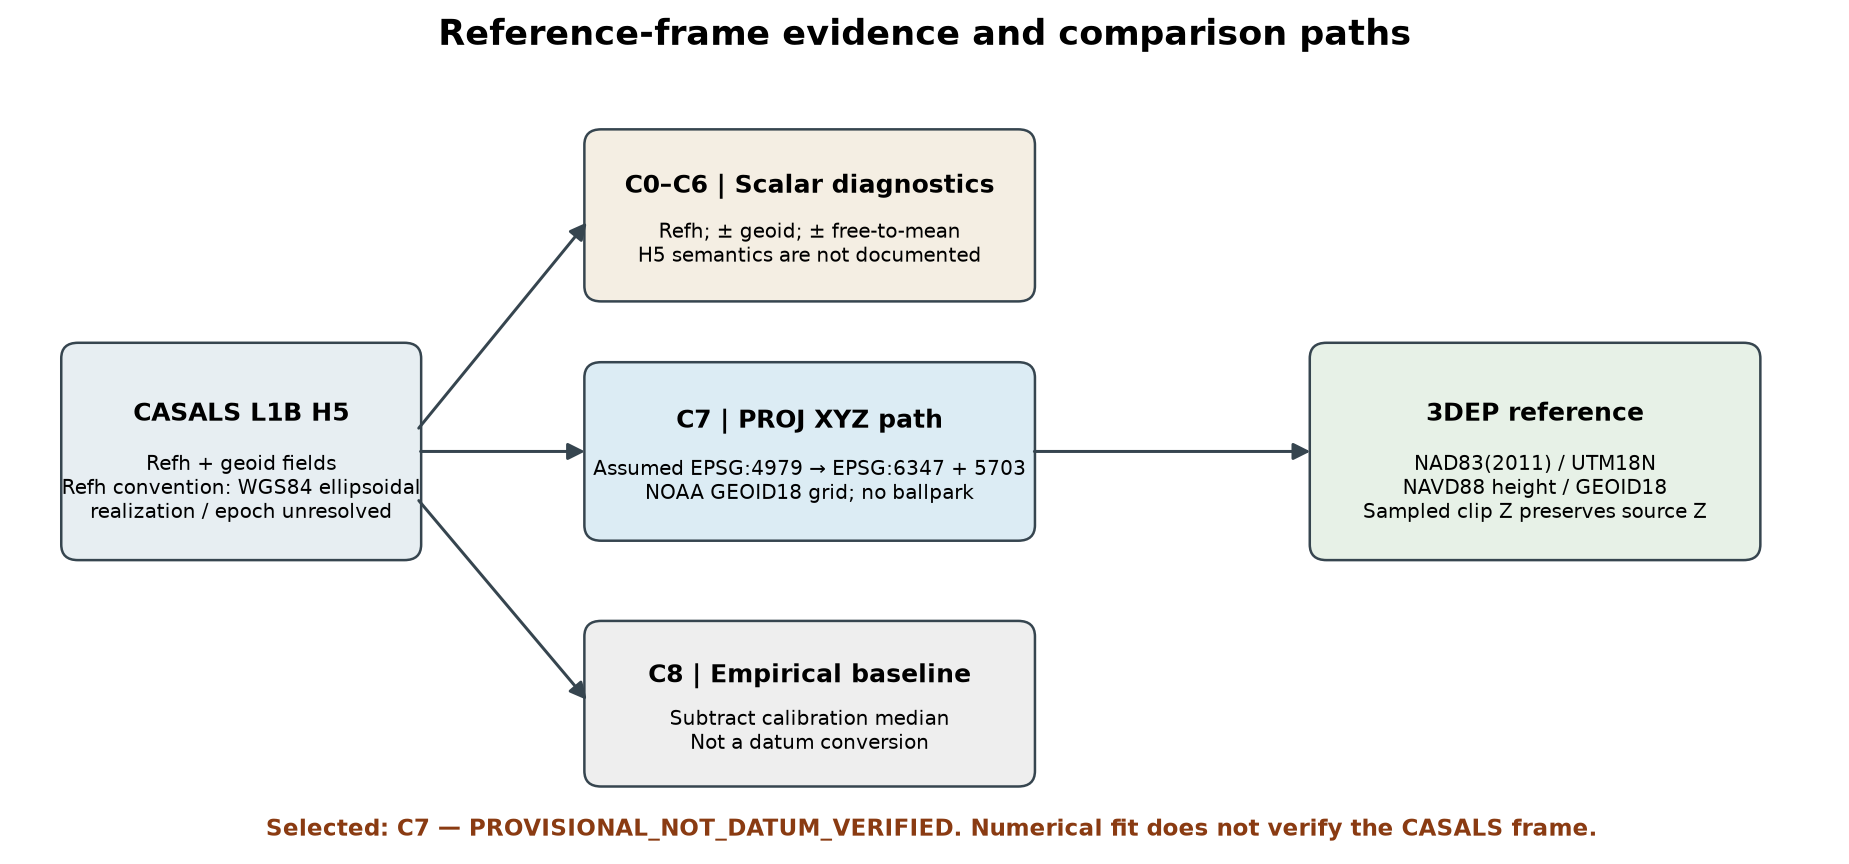

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "research").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from research.reference.vertical_datum_comparison import OUTPUT_ROOT, run_datum_comparison

OUT = OUTPUT_ROOT
RUN = run_datum_comparison(output_dir=OUT, make_figures=True)
SUMMARY = RUN["summary"]

def date_label(granule_id):
    return "2024-11-12" if "20241112" in granule_id else "2024-11-18"

# Keep file hashes separate from the compact field summary.
h5_rows = []
field_rows = []
for granule_id, item in RUN["h5_audit"]["granules"].items():
    fields = item["field_audit"]
    formula = item["free_to_mean_formula_comparison"]["observed_minus_formula_m"]
    h5_rows.append({"granule": date_label(granule_id), "pulse count": item["root_attributes"]["n_pulses"], "H5 SHA-256": item["source_sha256"]})
    for field_name in ["refh", "geoid", "geoid_free2mean"]:
        field = fields[field_name]
        field_rows.append({
            "granule": date_label(granule_id),
            "field": field_name,
            "units": field["units"],
            "H5 attributes": field["attributes"],
            "median (m)": field["stats"]["median"],
            "max |free2mean − formula| (m)": max(abs(formula["min"]), abs(formula["max"])) if field_name == "geoid_free2mean" else None,
        })
display(pd.DataFrame(h5_rows))
display(pd.DataFrame(field_rows).round(7))

# Product metadata and sampled source-to-clip Z identity checks.
z_audit = RUN["z_audit"]
z_rows = []
for granule_id, item in z_audit["granules"].items():
    product = item["work_unit_and_product_evidence"]
    points = item["point_identity_z_check"]
    z_rows.append({
        "granule": date_label(granule_id),
        "work unit": item.get("work_unit"),
        "project": item.get("project"),
        "target vertical CRS": product.get("vertical_crs"),
        "geoid model": product.get("geoid_model"),
        "metadata conflict": product.get("metadata_conflict"),
        "identity matches": points["identity_match_count"],
        "median ΔZ (m)": points["delta_z_m"]["median"],
        "max |ΔZ| (m)": max(abs(points["delta_z_m"]["min"]), abs(points["delta_z_m"]["max"])),
        "max ΔXY (m)": points["delta_xy_m"]["max"],
    })
display(pd.DataFrame(z_rows).round(6))
print("Sampled Z status:", z_audit["overall_status"], "— 0.01 m LAS quantization tolerance; sample only.")

# Show the product-matched operation separately from higher-ranked alternatives.
def alternate_grid_family(grids):
    names = " ".join(g["name"].lower() for g in grids)
    if "g1999" in names:
        return "GEOID99 + NADCON5"
    if "geoid03" in names:
        return "GEOID03 + NADCON5"
    return ", ".join(g["name"] for g in grids) or "no grid listed"

operation_rows = []
roundtrip_rows = []
for granule_id, item in RUN["coordinate_operations"].items():
    if "c7" not in item:
        continue
    audit = item["c7"]
    top = audit["all_available_operations"][0]
    operation_rows.append({
        "granule": date_label(granule_id),
        "C7 rank": audit["selected_operation_ranked_index"] + 1,
        "C7 accuracy (m)": audit["selected_accuracy_m"],
        "C7 grid": ", ".join(g["name"] for g in audit["selected_operation_grids"]),
        "top alternative": alternate_grid_family(top["required_grids"]),
        "alternative accuracy (m)": top["accuracy_m"],
        "available / unavailable": f"{audit['transformer_count']} / {audit['unavailable_operations_count']}",
    })
    roundtrip_rows.append({
        "granule": date_label(granule_id),
        "max inverse XY error (m)": audit["round_trip"]["horizontal_error_m"]["max"],
        "max inverse Z error (m)": max(abs(audit["round_trip"]["vertical_error_m"]["min"]), abs(audit["round_trip"]["vertical_error_m"]["max"])),
        "median vertical correction (m)": audit["vertical_change_m"]["median"],
        "max XY shift (m)": audit["xy_shift_vs_existing_epsg6347_m"]["max"],
    })
display(pd.DataFrame(operation_rows).round(8))
display(pd.DataFrame(roundtrip_rows).round(9))

split = json.loads((OUT / "selection_split_manifest_audit.json").read_text(encoding="utf-8"))
print("Frozen split SHA-256:", split["manifest_sha256"])
split_rows = []
for key, count in split["role_counts"].items():
    granule_id, role = key.split("::")
    split_rows.append({"granule": date_label(granule_id), "role": role, "pulse count": count})
display(pd.DataFrame(split_rows))
print("Output directory:", OUT)
print("Artifact files including manifest:", len(SUMMARY["output_files"]))
display(Image(filename=str(OUT / "figures" / "reference_frame_overview.png")))

## 2. Height-Conversion Candidates

C0–C6 are native or scalar diagnostics. Their equations are tested on identical original pulse IDs and common 3DEP support. C7 is a real XYZ transform to EPSG:6347 + EPSG:5703 and is constrained to the NOAA GEOID18 grid named by the 3DEP product metadata. C8 subtracts an offset fit on a separate calibration half; it remains an empirical comparison and never competes in geodetic selection.

,candidate_id,formula,target,selection_class,evidence_status
0,C0,Refh,none; native stored values,baseline,unresolved source vertical frame
1,C1,Refh - geoid,H5 geoid field candidate,diagnostic,H5 geoid model/units/frame/application unresolved
2,C2,Refh + geoid,H5 geoid field candidate,diagnostic,sign sensitivity only
3,C3,Refh - geoid - geoid_free2mean,H5 fields,diagnostic,both H5 field semantics unresolved
4,C4,Refh - geoid + geoid_free2mean,H5 fields,diagnostic,both H5 field semantics unresolved
5,C5,Refh + geoid - geoid_free2mean,H5 fields,diagnostic,both H5 field semantics unresolved
6,C6,Refh + geoid + geoid_free2mean,H5 fields,diagnostic,both H5 field semantics unresolved
7,C7,TransformerGroup(EPSG:4979 assumption) → EPSG:...,EPSG:6347 + EPSG:5703,provisional geodetic path,target and operation evidenced; CASALS realiza...
8,C8,Refh - median(C0 residual on calibration_offset),empirical relative alignment,separate empirical baseline; never competes fo...,not a datum transformation


H5 `geoid` and `geoid_free2mean` have no field-level units or model semantics. The figure compares their values with NOAA GEOID18 samples and the observed free-to-mean formula; the numerical correspondences do not define the H5 fields.

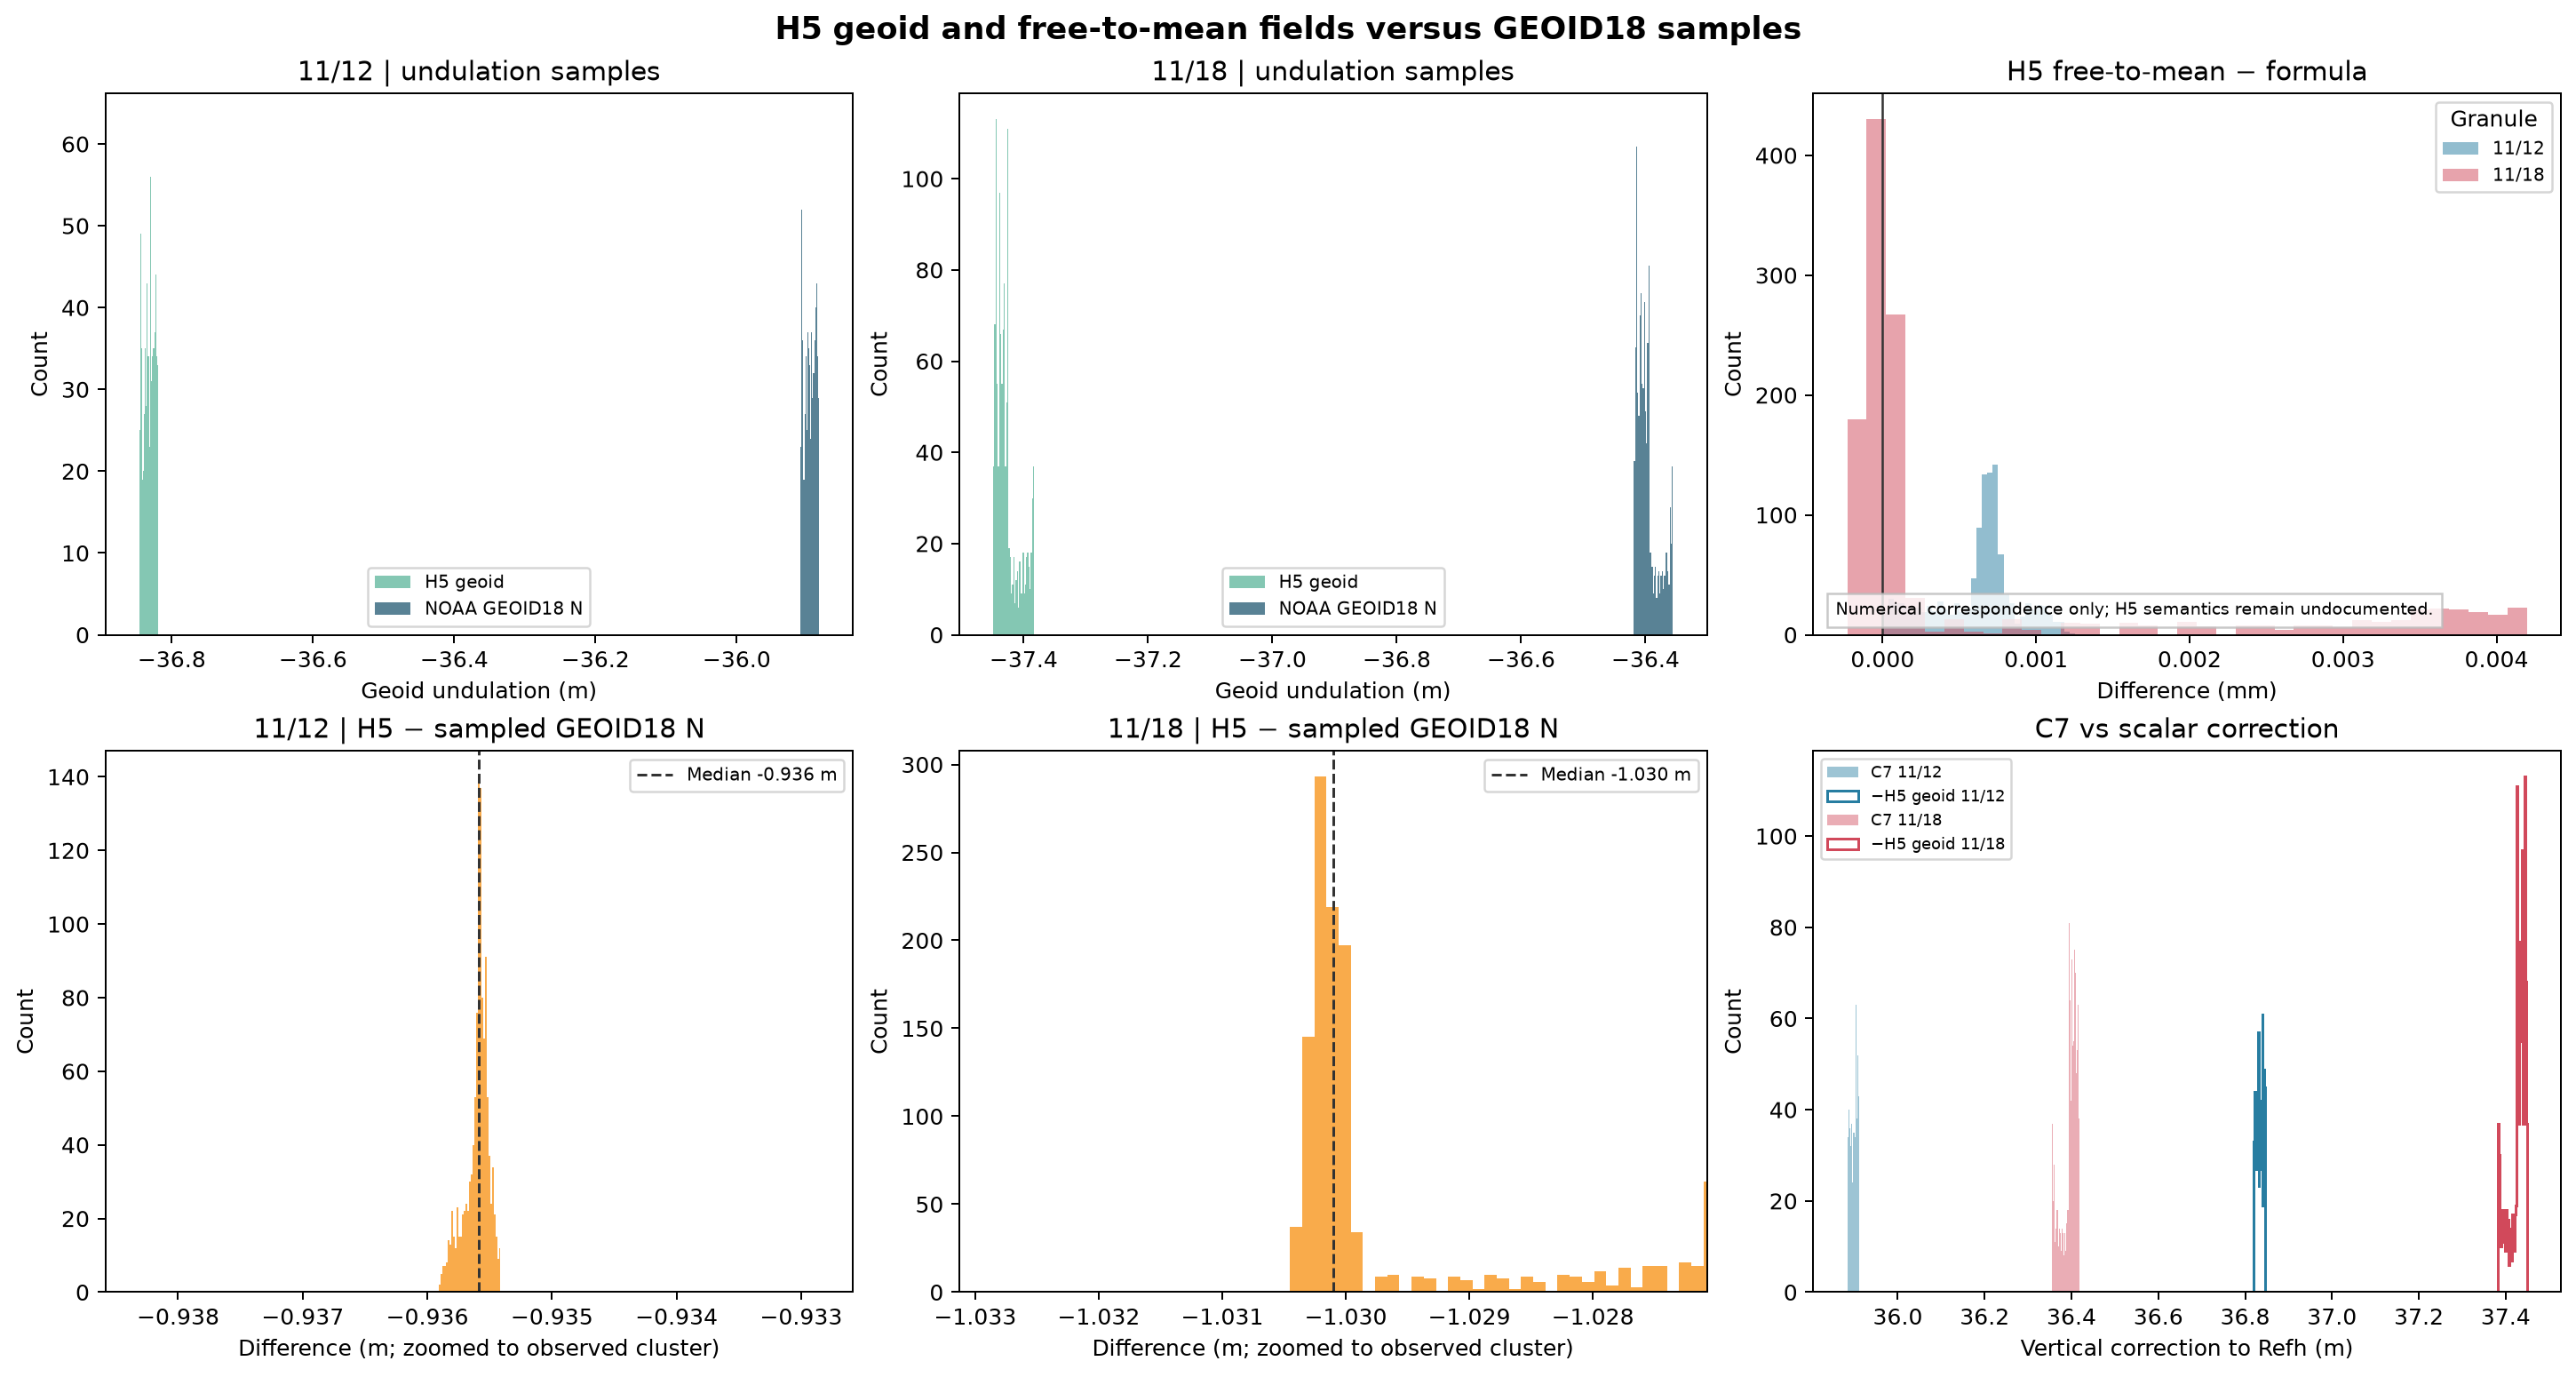

In [2]:
candidate_manifest = json.loads((OUT / "vertical_candidate_manifest.json").read_text(encoding="utf-8"))
display(pd.DataFrame(candidate_manifest["candidate_definitions"]))
display(Markdown(
    "H5 `geoid` and `geoid_free2mean` have no field-level units or model semantics. "
    "The figure compares their values with NOAA GEOID18 samples and the observed free-to-mean formula; "
    "the numerical correspondences do not define the H5 fields."
))
display(Image(filename=str(OUT / "figures" / "geoid_correction_comparison.png")))

## 3. Configuration Comparison

Candidate metrics use the frozen `candidate_selection` spatial half only. The SNR ≥ 3 table is the primary numerical comparison; SNR ≥ 5 is included as a second declared stratum. Each row uses the same pulse IDs across C0–C7, the same original and C7-requeried local-plane support, and uncorrected residuals.

,date,snr_stratum,candidate_id,n,bias_m,rmse_m,mae_m,nmad_m,abs_p95_m
8,2024-11-12,snr_ge_3,C0,3157,-37.7042,37.9247,37.7839,0.1143,37.8905
9,2024-11-12,snr_ge_3,C1,3157,-0.8746,4.1766,1.0243,0.1144,1.0613
10,2024-11-12,snr_ge_3,C2,3157,-74.5338,74.6456,74.5711,0.1144,74.7199
11,2024-11-12,snr_ge_3,C3,3157,-0.8547,4.1725,1.0045,0.1144,1.0414
12,2024-11-12,snr_ge_3,C4,3157,-0.8945,4.1808,1.0442,0.1144,1.0811
13,2024-11-12,snr_ge_3,C5,3157,-74.5139,74.6257,74.5513,0.1144,74.7000
14,2024-11-12,snr_ge_3,C6,3157,-74.5536,74.6654,74.5910,0.1144,74.7398
15,2024-11-12,snr_ge_3,C7,3157,-1.8102,4.4672,1.9581,0.1144,1.9968
16,2024-11-12,snr_ge_5,C0,208,-37.6695,37.6696,37.6695,0.0884,37.8332
17,2024-11-12,snr_ge_5,C1,208,-0.8400,0.8461,0.8400,0.0881,1.0037


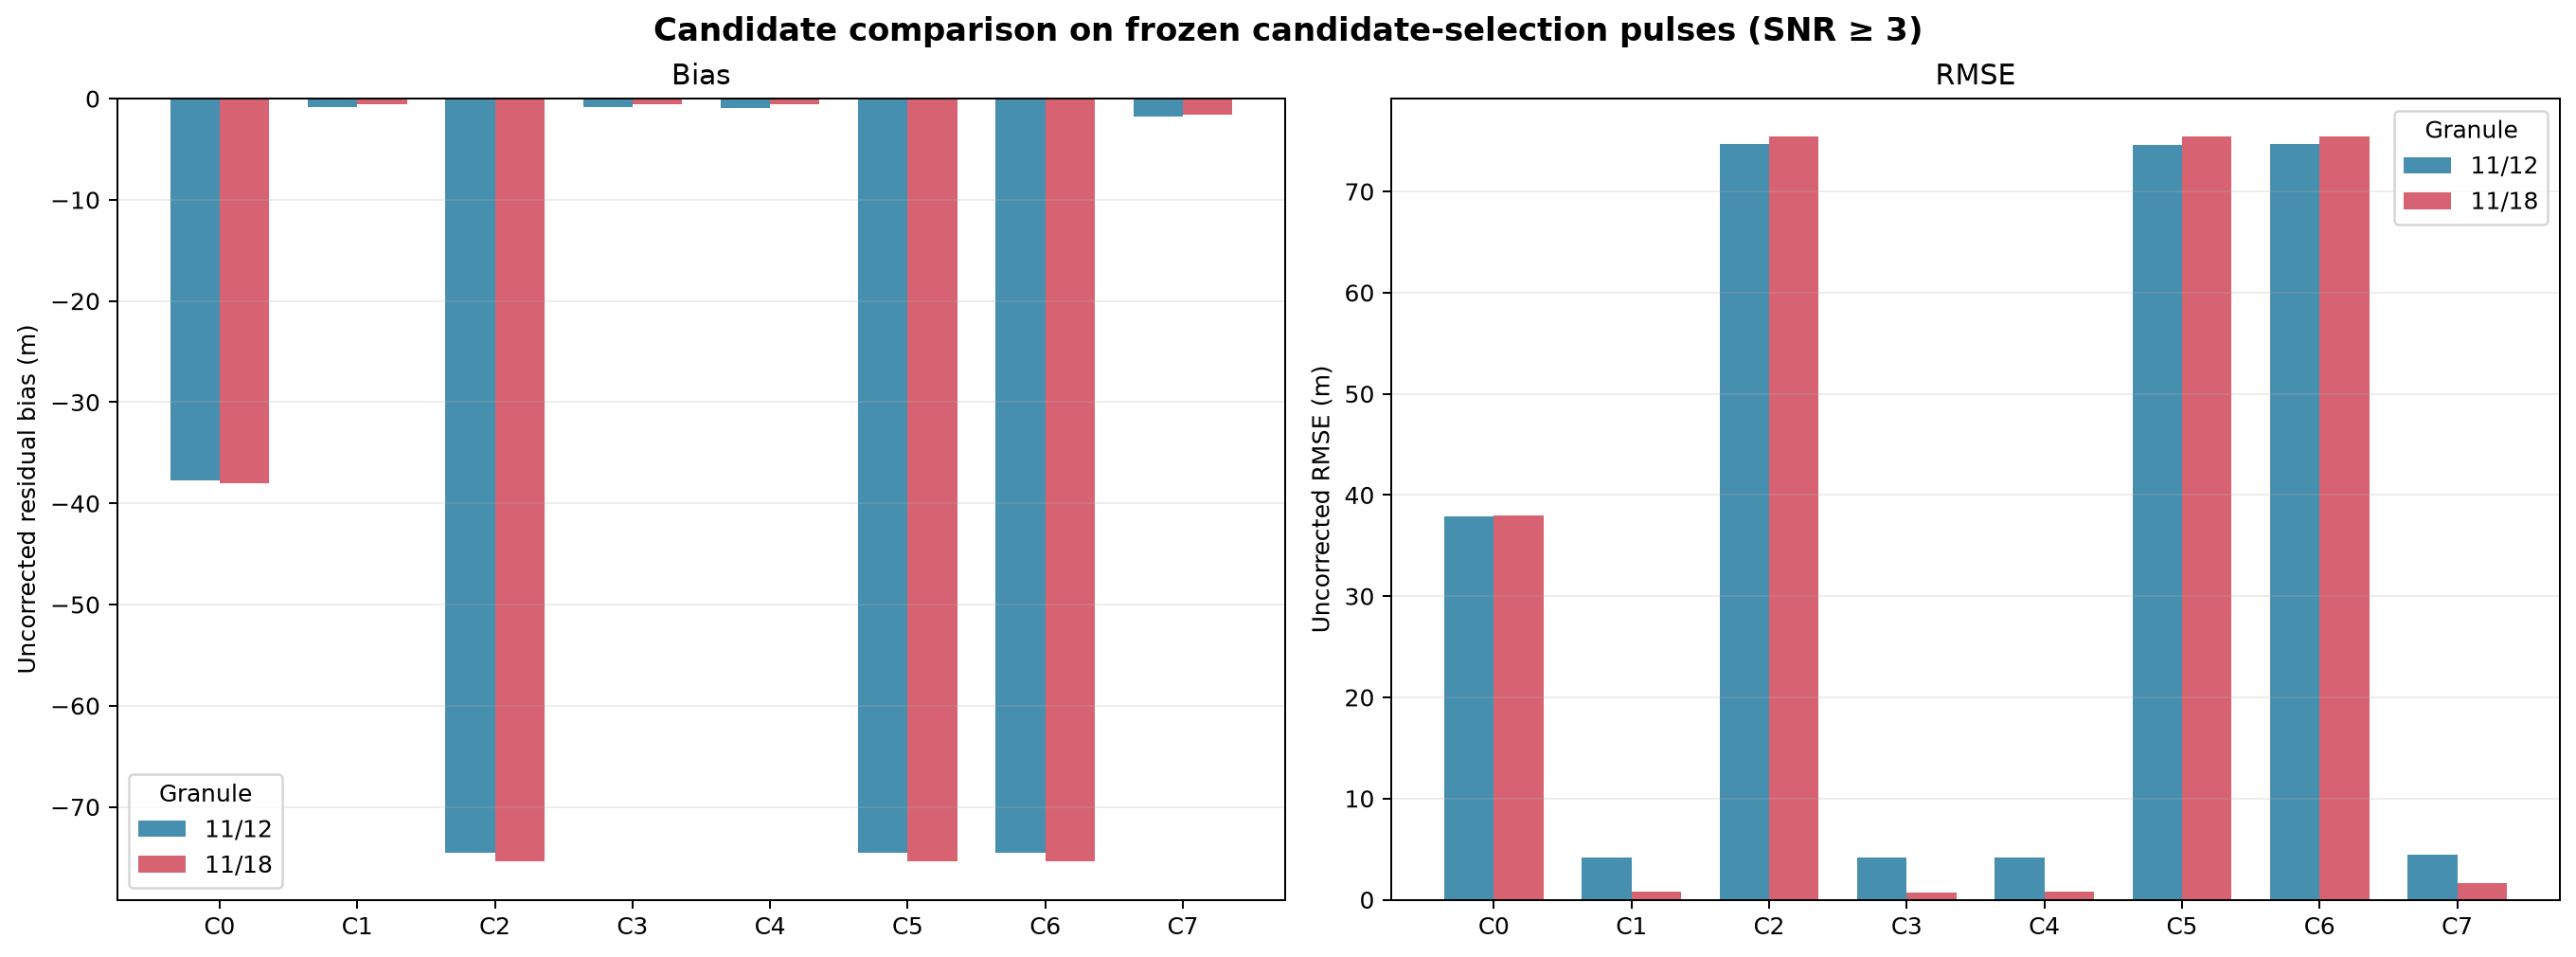

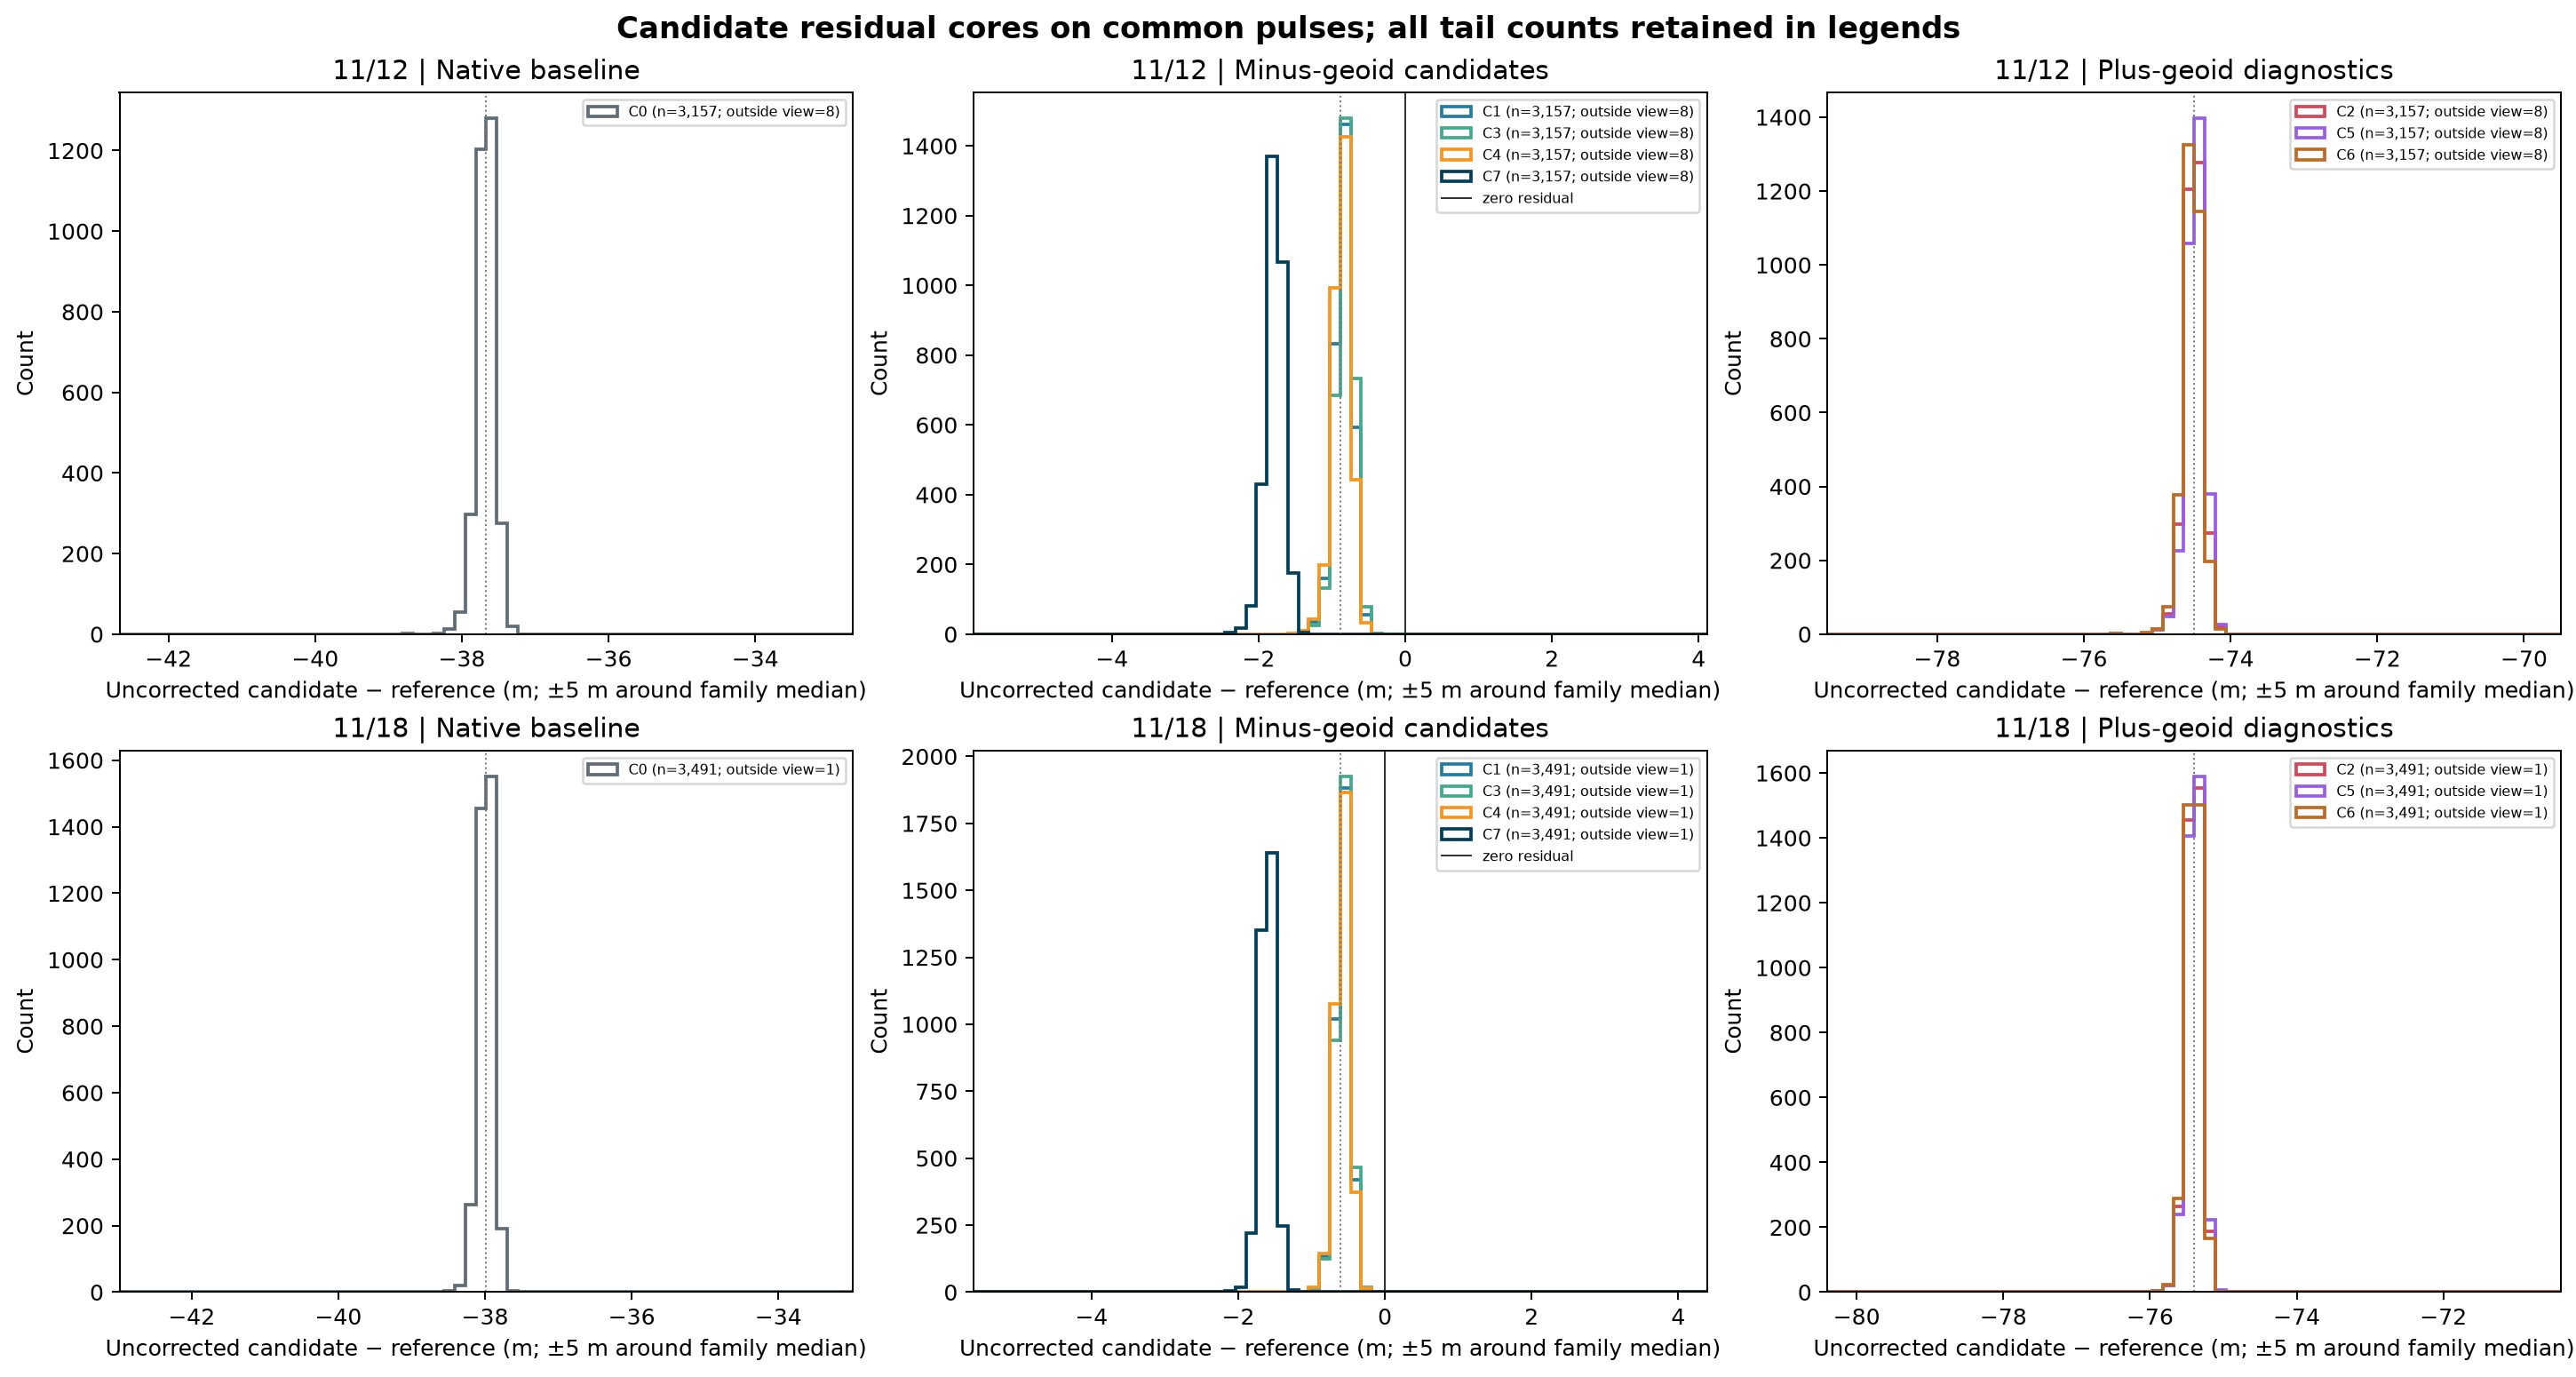

In [3]:
candidate_metrics = RUN["candidate_metrics"]
selection_metrics = candidate_metrics.loc[
    (candidate_metrics.research_role == "candidate_selection")
    & candidate_metrics.snr_stratum.isin(["snr_ge_3", "snr_ge_5"])
].copy()
selection_metrics["date"] = selection_metrics.granule_id.map(date_label)
selection_view = selection_metrics[[
    "date", "snr_stratum", "candidate_id", "n", "bias_m", "rmse_m", "mae_m", "nmad_m", "abs_p95_m"
]].sort_values(["date", "snr_stratum", "candidate_id"])
display(selection_view.round(4))
display(Image(filename=str(OUT / "figures" / "candidate_bias_rmse_comparison.png")))
display(Image(filename=str(OUT / "figures" / "candidate_residual_distributions.png")))

## 4. Configuration Selection

Selection prioritizes a complete, physically plausible operation tied to the documented target product. Candidate-selection metrics are secondary checks. Independent-test results are not inputs to selection, and C8 is excluded from the geodetic candidate set.

In [4]:
selected = json.loads((OUT / "selected_vertical_configuration.json").read_text(encoding="utf-8"))
selection_summary = {
    "candidate": selected["candidate_id"],
    "status": selected["status"],
    "source CRS assumption": selected["source_crs"],
    "source realization": selected["source_realization"],
    "source coordinate epoch": selected["source_coordinate_epoch"],
    "target CRS": selected["target_crs"],
    "target vertical reference": selected["target_vertical"],
    "operation accuracy (m)": selected["operation_by_granule"][next(iter(selected["operation_by_granule"]))]["accuracy_m"],
    "test metrics used": selected["test_metrics_used"],
    "split SHA-256": selected["split_manifest_sha256"],
    "configuration SHA-256": selected["configuration_sha256"],
}
display(pd.DataFrame([selection_summary]).T.rename(columns={0: "value"}))
print(selected["selection_reason"])
primary_selection = pd.DataFrame(selected["selection_metrics_primary"])
display(primary_selection[["granule_id", "candidate_id", "snr_stratum", "n", "bias_m", "rmse_m", "nmad_m"]].round(4))

,value
candidate,C7
status,PROVISIONAL_NOT_DATUM_VERIFIED
source CRS assumption,EPSG:4979 WGS 84 3D ensemble (assumed; not ver...
source realization,None
source coordinate epoch,None
target CRS,EPSG:6347 + EPSG:5703
target vertical reference,"EPSG:5703 NAVD88 height, GEOID18"
operation accuracy (m),2.015
test metrics used,False
split SHA-256,cd714dd3057193bc9f510dfa34adfe19b2c28db628f2b9...


No candidate has verified CASALS source realization and coordinate epoch; the highest-ranked physically plausible available path is retained provisionally, with selection-site numerical agreement as a check rather than datum proof.


,granule_id,candidate_id,snr_stratum,n,bias_m,rmse_m,nmad_m
0,casals_l1b_20241112T165718_001_02,C7,all_valid_refh,8987,-5.1570,49.8140,0.1893
1,casals_l1b_20241112T165718_001_02,C7,snr_ge_3,3157,-1.8102,4.4672,0.1144
2,casals_l1b_20241112T165718_001_02,C7,snr_ge_5,208,-1.7755,1.7784,0.0881
3,casals_l1b_20241118T171757_001_02,C7,all_valid_refh,3570,0.6861,20.0031,0.0958
4,casals_l1b_20241118T171757_001_02,C7,snr_ge_3,3491,-1.5959,1.6713,0.0934
5,casals_l1b_20241118T171757_001_02,C7,snr_ge_5,3124,-1.6015,1.6043,0.0908


## 5. Final Elevation Validation

Only after `selected_vertical_configuration.json` was written were the independent-test metrics calculated. The table retains C7, native C0, and C8 as separate configurations. Coverage is common supported pulses divided by the predeclared independent-test denominator; no gross residuals are filtered.

,date,configuration_id,snr_stratum,n_common_support,n_denominator_independent_test,coverage,bias_m,rmse_m,mae_m,nmad_m,abs_p95_m,gross_error_rate_gt_2m,previous_full_calibration_rmse_m,selected_rmse_minus_previous_empirical_m,c8_rmse_minus_previous_empirical_m
1,2024-11-12,C0,all_valid_refh,14885,17171,0.86687,-13.45456,81.89535,64.76093,0.29543,180.35388,0.99684,84.33182,NaN,NaN
0,2024-11-12,C7,all_valid_refh,14885,17171,0.86687,22.44774,83.84343,45.97650,0.29569,207.41523,0.40894,84.33182,-0.48840,NaN
2,2024-11-12,C8,all_valid_refh,14885,17171,0.86687,24.19191,84.32717,45.20763,0.29543,209.15958,0.37931,84.33182,NaN,-0.00466
4,2024-11-12,C0,snr_ge_3,4274,4852,0.88087,-37.38895,38.34684,37.87813,0.11739,37.81361,1.00000,8.52172,NaN,NaN
3,2024-11-12,C7,snr_ge_3,4274,4852,0.88087,-1.48660,8.64618,2.16735,0.11732,1.91466,0.02106,8.52172,0.12446,NaN
5,2024-11-12,C8,snr_ge_3,4274,4852,0.88087,0.25894,8.52136,0.60045,0.11739,0.27261,0.00468,8.52172,NaN,-0.00036
7,2024-11-12,C0,snr_ge_5,445,478,0.93096,-37.57287,37.57301,37.57287,0.08764,37.75289,1.00000,0.13214,NaN,NaN
6,2024-11-12,C7,snr_ge_5,445,478,0.93096,-1.67051,1.67353,1.67051,0.08769,1.85075,0.00000,0.13214,1.54139,NaN
8,2024-11-12,C8,snr_ge_5,445,478,0.93096,0.05128,0.11284,0.09238,0.08764,0.21360,0.00000,0.13214,NaN,-0.01930
10,2024-11-18,C0,all_valid_refh,8924,8924,1.00000,-36.43287,41.11730,39.19603,0.09487,38.21314,0.99944,19.12256,NaN,NaN


,date,n_common_support,rmse_m,previous_full_calibration_rmse_m,c8_rmse_minus_previous_empirical_m
8,2024-11-12,445,0.11284,0.13214,-0.01930
17,2024-11-18,6615,0.09778,0.09663,0.00116


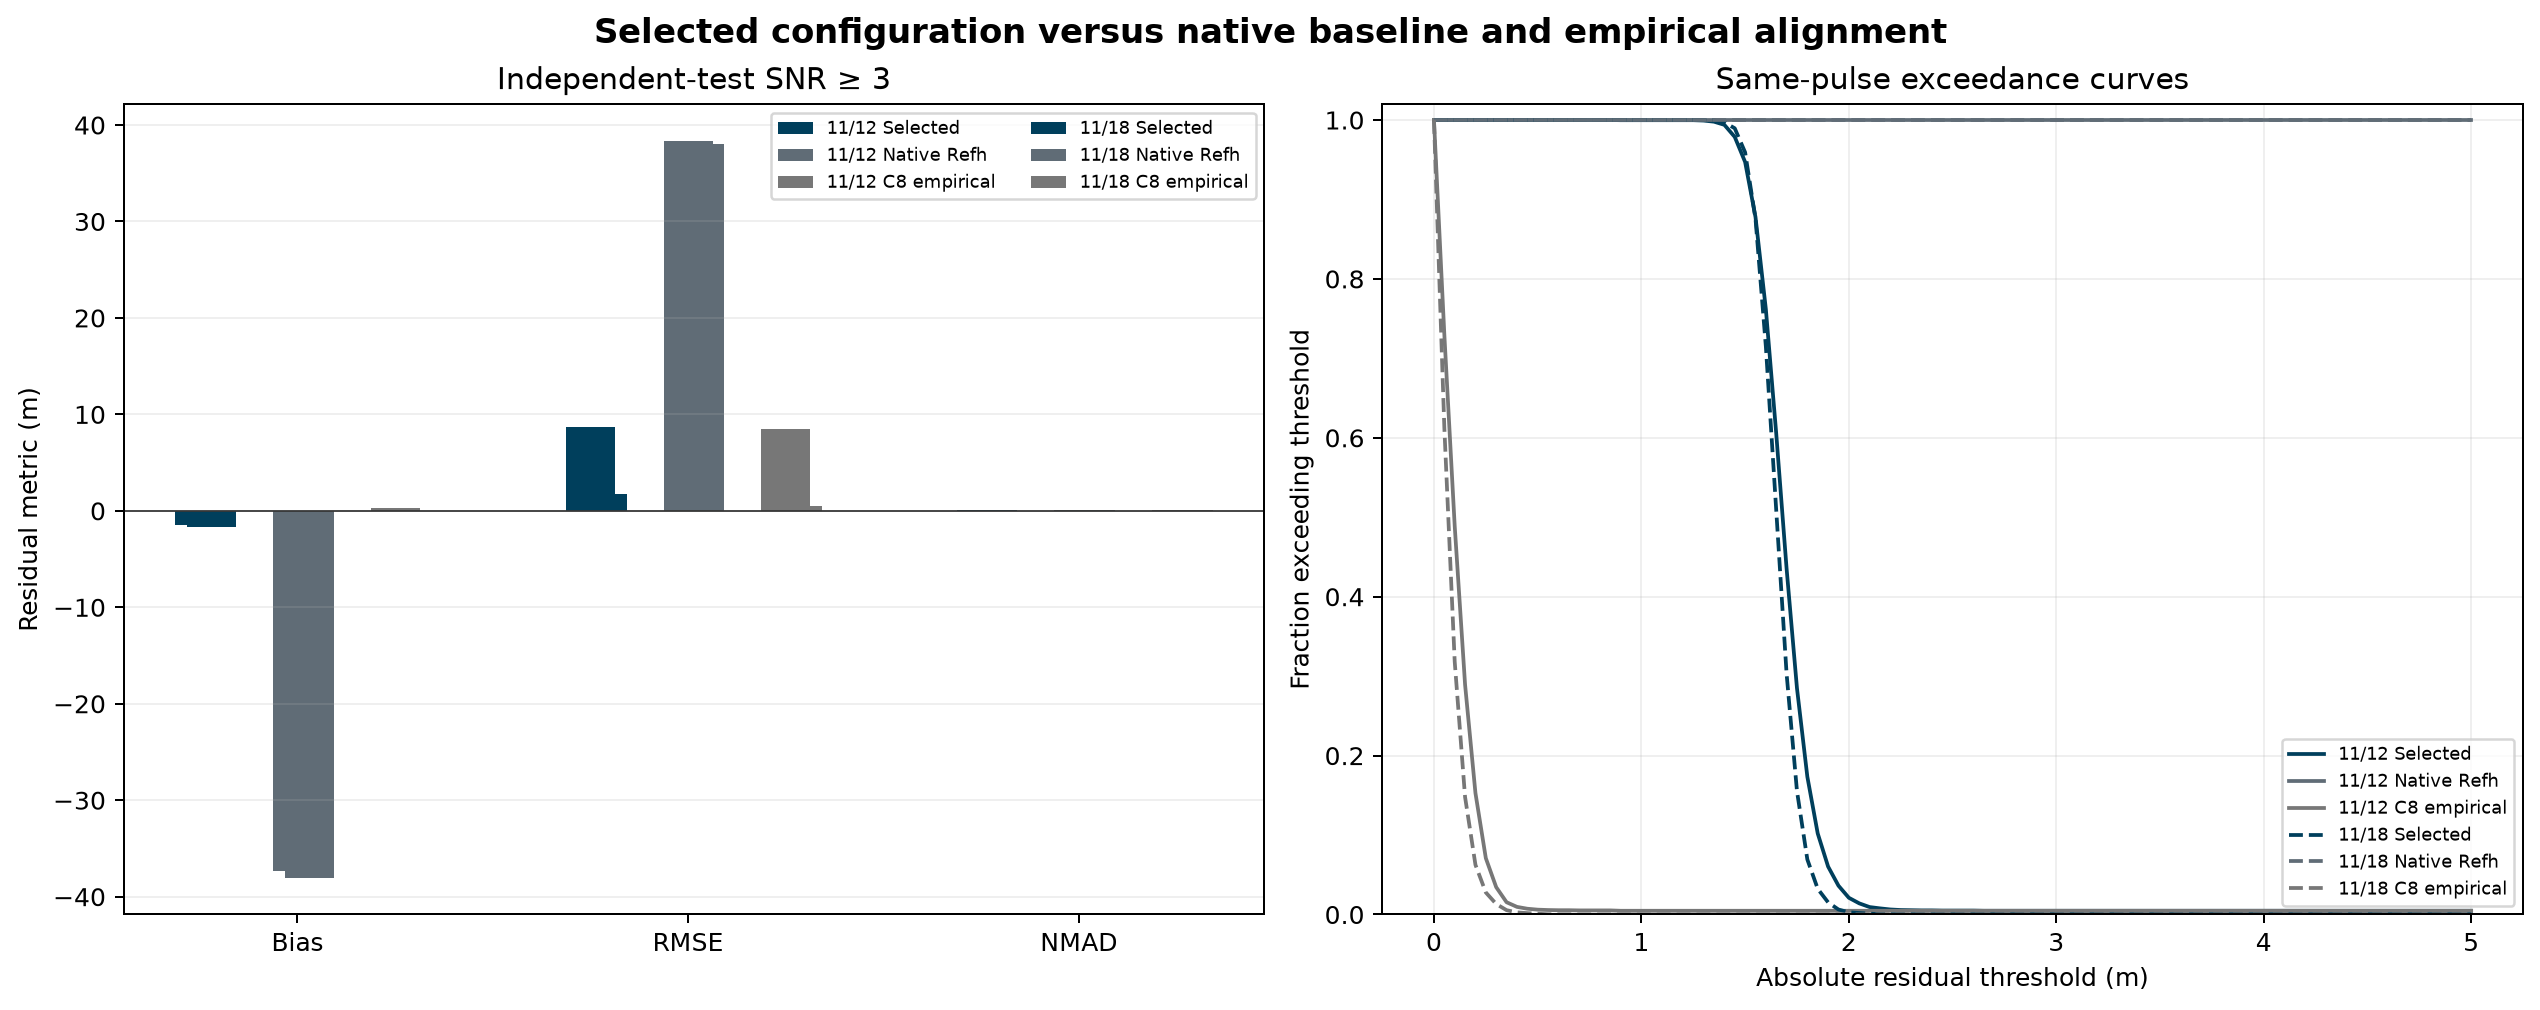

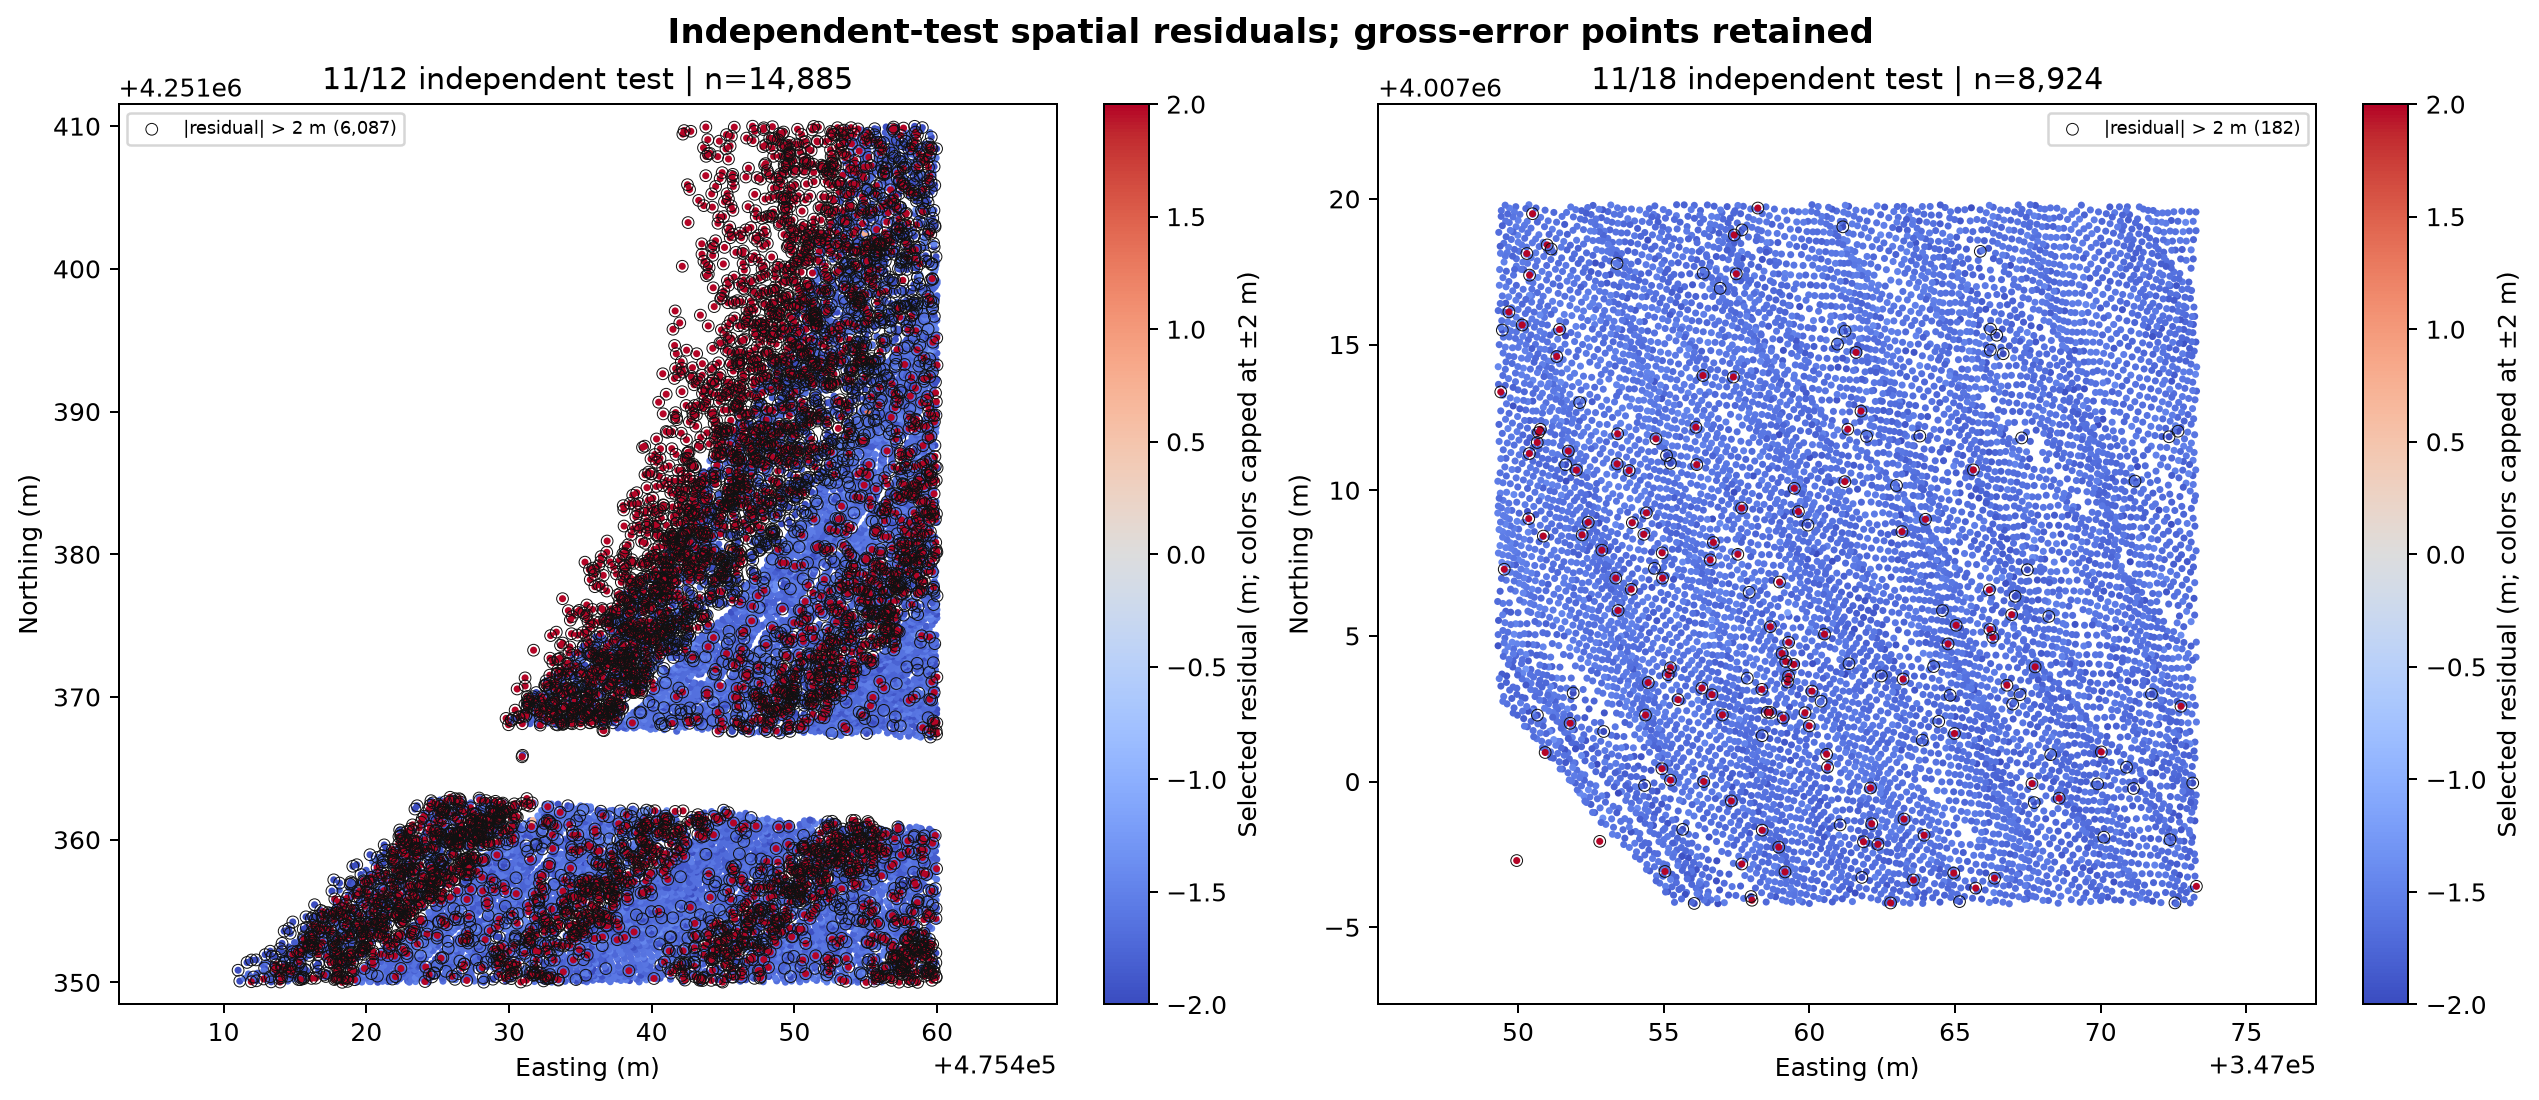

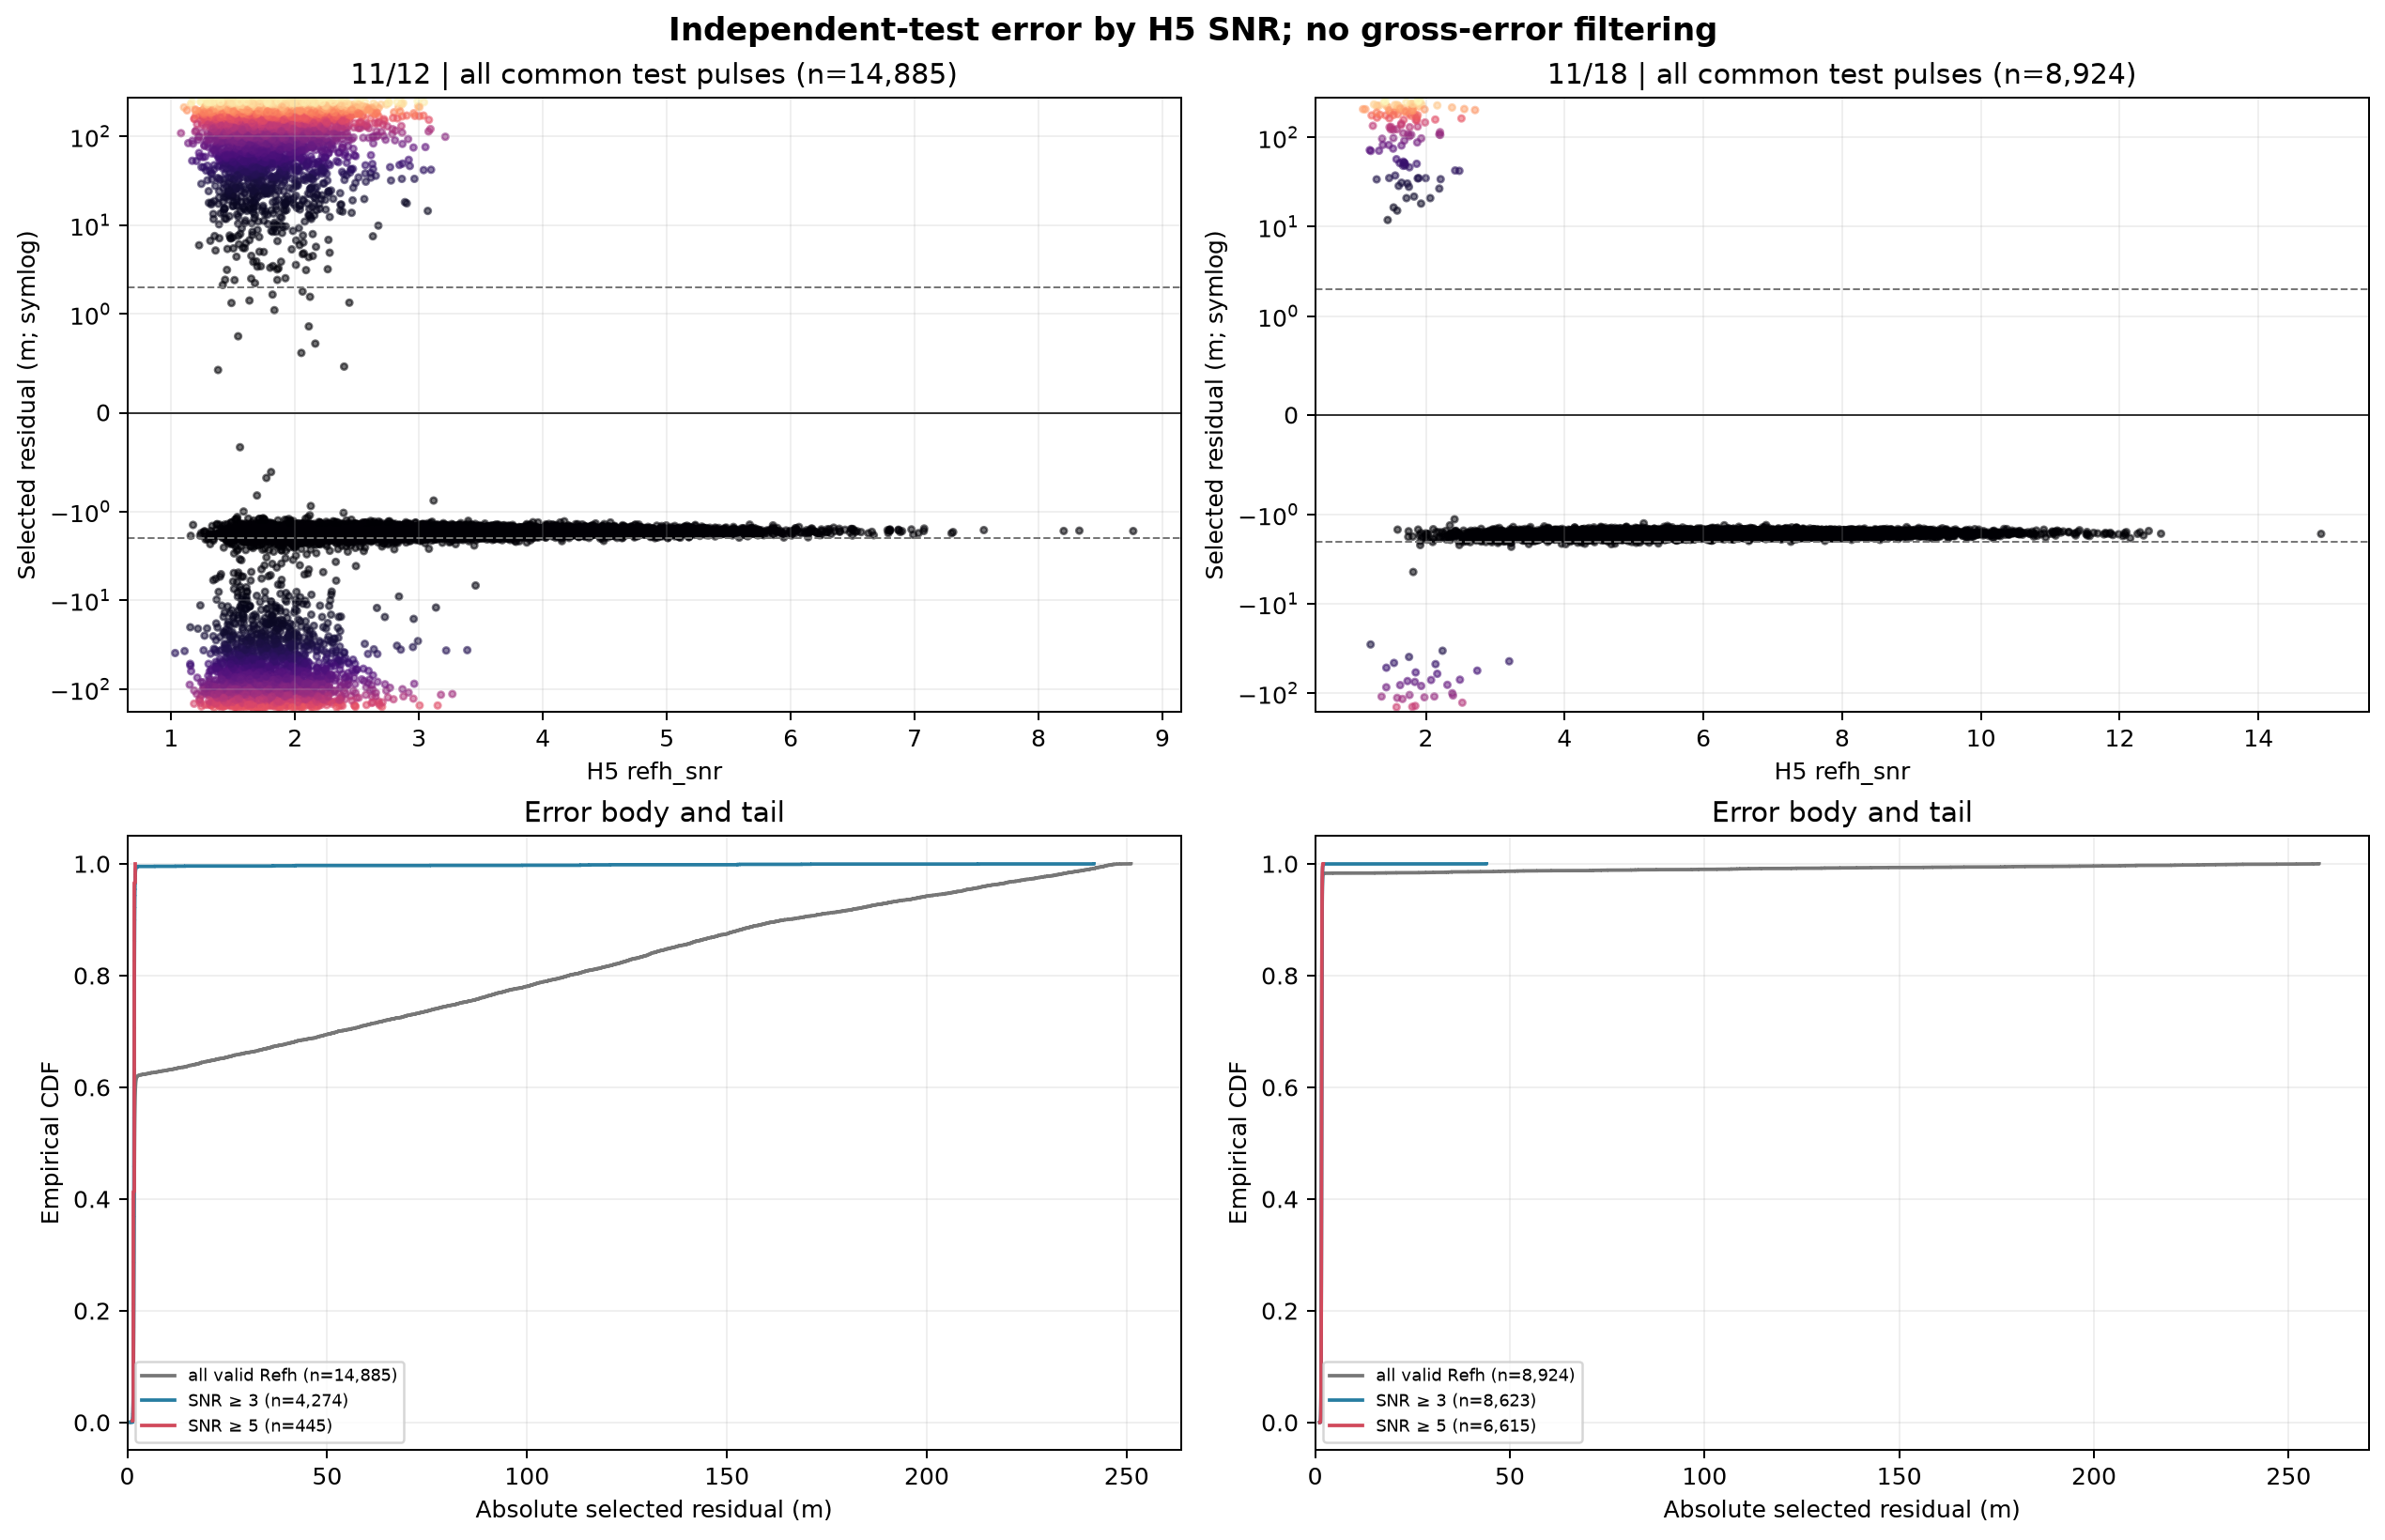

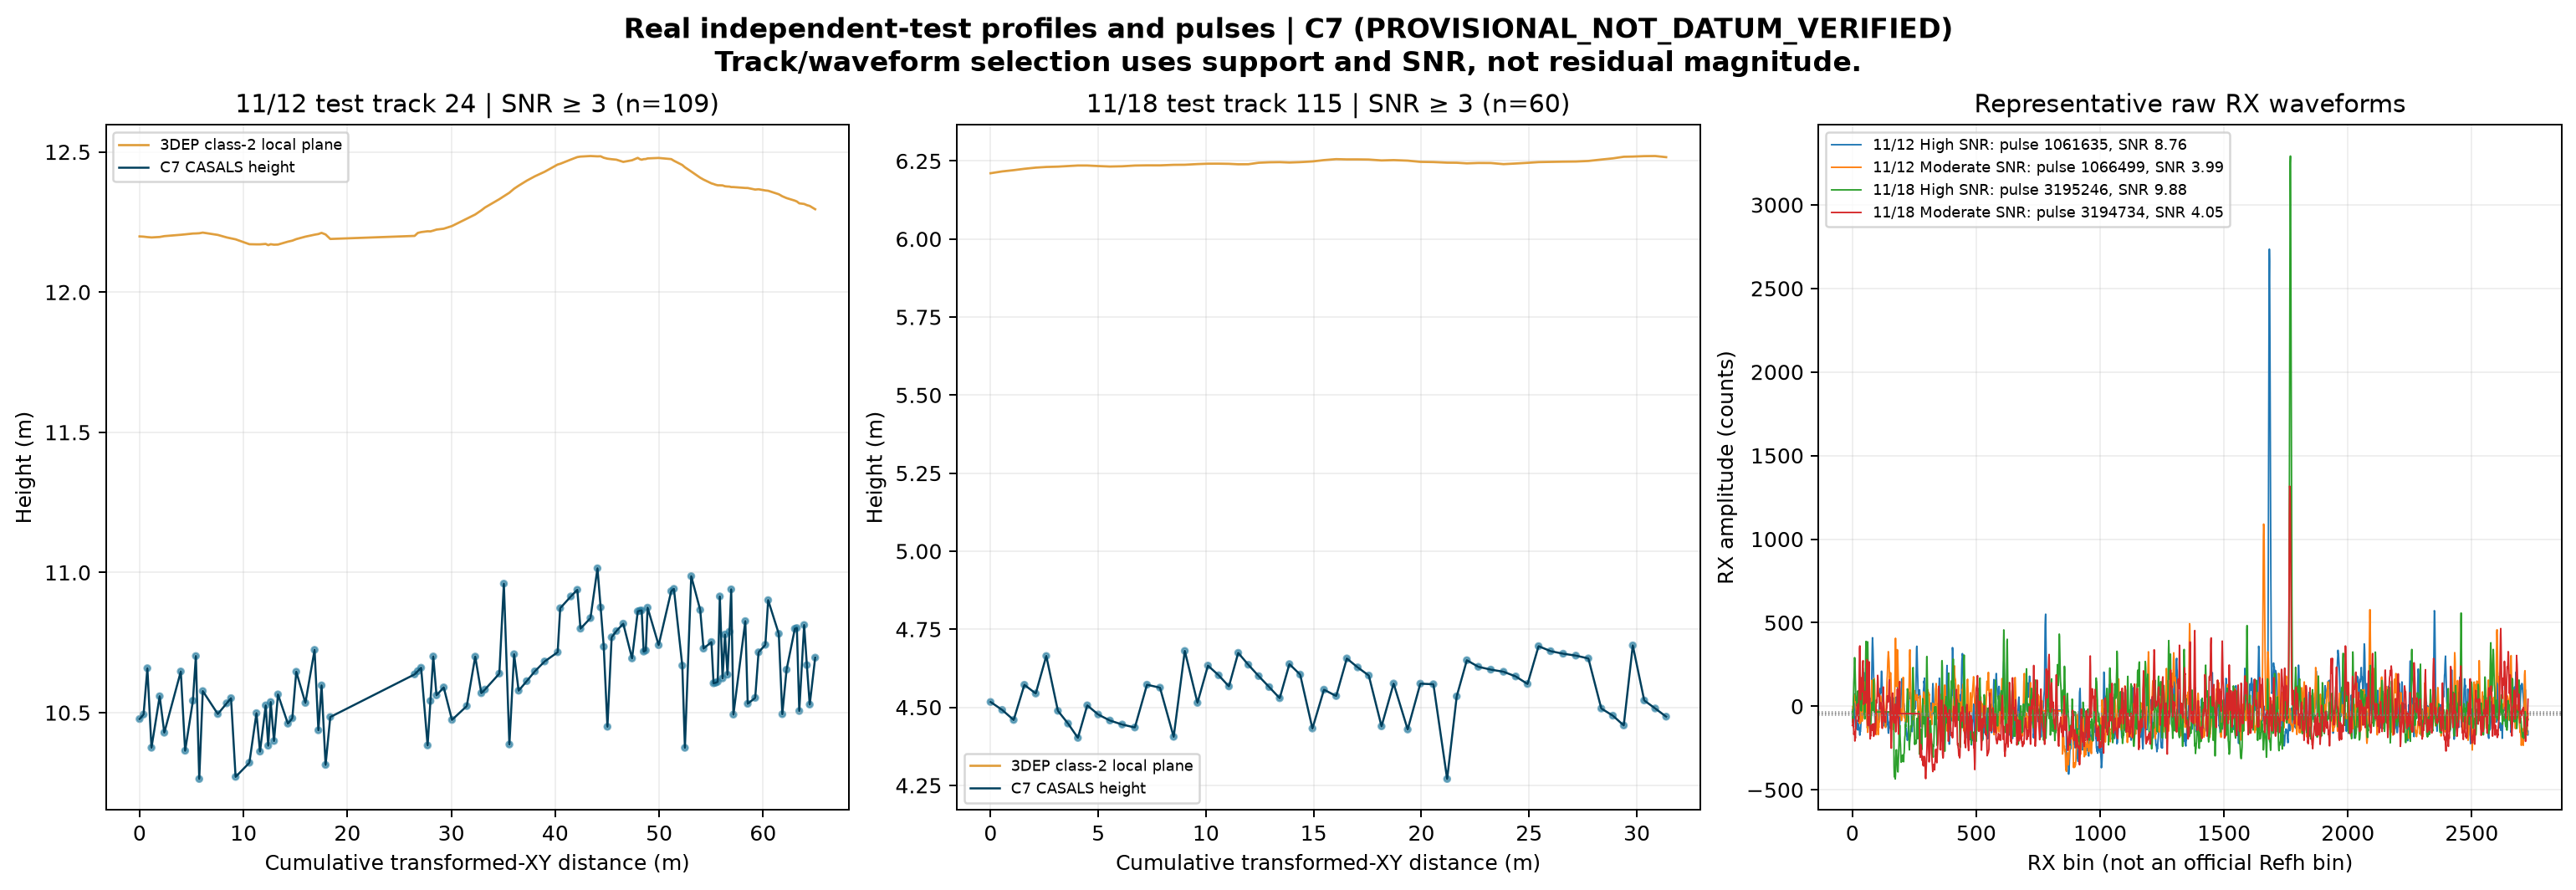

In [5]:
final_metrics = RUN["final_metrics"].copy()
final_metrics["date"] = final_metrics.granule_id.map(date_label)
final_view = final_metrics.loc[final_metrics.configuration_id.isin(["C7", "C0", "C8"]), [
    "date", "configuration_id", "snr_stratum", "n_common_support", "n_denominator_independent_test",
    "coverage", "bias_m", "rmse_m", "mae_m", "nmad_m", "abs_p95_m", "gross_error_rate_gt_2m",
    "previous_full_calibration_rmse_m", "selected_rmse_minus_previous_empirical_m", "c8_rmse_minus_previous_empirical_m"
]].sort_values(["date", "snr_stratum", "configuration_id"])
display(final_view.round(5))

# Current C8 versus the prior full-calibration empirical result, joined by SNR stratum.
c8_comparison = final_view.loc[
    (final_view.configuration_id == "C8") & (final_view.snr_stratum == "snr_ge_5"),
    ["date", "n_common_support", "rmse_m", "previous_full_calibration_rmse_m", "c8_rmse_minus_previous_empirical_m"]
]
display(c8_comparison.round(5))

for filename in [
    "selected_vs_baseline.png",
    "final_residual_spatial_maps.png",
    "final_error_snr.png",
    "final_ground_profile.png",
]:
    display(Image(filename=str(OUT / "figures" / filename)))

## 6. Interpretation and Limitations

C7 follows the documented NAVD88/GEOID18 target and is the selected path, but EPSG:4979 is only an assumed CASALS source frame. The H5 does not identify its WGS84 realization, coordinate epoch, or whether named geoid/tide fields are already applied to `Refh`. The selected operation's 2.015 m accuracy is PROJ metadata, and the inverse round-trip only checks numerical consistency.

C3 had the lowest selection-site numerical RMSE in both granules. That result does not establish that the H5 scalar fields are physically correct. C8's smaller independent-test residuals are expected from site-specific empirical calibration and do not establish a datum conversion. On the independent test, C7 SNR ≥ 5 RMSE is about 1.67 m for both dates while NMAD is about 0.088 m; the retained low-SNR tails increase the SNR ≥ 3 and all-valid RMSE substantially. These statistics describe agreement with the local 3DEP surfaces under this sample and support definition, not absolute accuracy.

The Z-preservation check covers 11,871 and 11,775 identity-matched points, not every clipped LAZ point. The Maryland vendor XML's generic GEOID12B entry conflicts with the product summary/final report's GEOID18 identification and remains disclosed. Scope is two granules and local open-field holdouts. Follow-up source-frame documentation and broader checkpoints are required before treating C7 as datum verified.

Full methods, evidence, and prior empirical results are in [the validation report](../docs/casals_l1b_validation_report.md).